## 10 — Hierarchical clustering versions of Figures 1 and 2 (exploratory)

### Aim
* `09_cibersortx_vs_xdec_k13_comparison.ipynb`'s Figures 1 and 2 deliberately disable clustering (`row_cluster=False, col_cluster=False`) and hold both axes in a fixed, known order (profile number; reference columns sorted by true cell type) — that fixed order is what makes them legible as validation checks against ground truth. This notebook asks a different, exploratory question instead: **does unsupervised hierarchical clustering on the correlation values themselves recover the same structure**, or does data-driven grouping disagree with the known cell-type labels anywhere?
* This is a companion to notebook 09, not a replacement — the fixed-order figures remain the validation reference; this notebook is for exploring whether clustering surfaces anything the fixed order hides or confirms it independently.

### Input
* Same as notebook 09: `xdec_autotuned_n150/stage1_k13/cell_type_profiles.tsv` (XDec k=13), `data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx/CIBERSORTx_sigmatrix_Adjusted.txt` (CIBERSORTx's own auto-selected-gene signature, label-shift corrected the same way), and the Run D pseudobulk reference (`refs_pseudobulk_raw.tsv` / `ref_metadata_pseudobulk_raw.tsv`)

### Output
* **Figure 1 (clustered)**: XDec k=13 profile × Run D reference correlation, both axes hierarchically clustered (average linkage, Euclidean distance on the correlation matrix), with dendrograms
* **Figure 2 (clustered)**: the same, for CIBERSORTx's own signature matrix

### Steps
* Rebuild both correlation matrices exactly as in notebook 09 (same genes, same label-shift fix)
* Render each with `row_cluster=True, col_cluster=True` and a visible dendrogram, keeping the cell-type color annotation on the reference axis so cluster purity against known labels remains checkable

### Result
* **Figure 2 (CIBERSORTx) independently recovers almost exactly the same three super-groups this whole investigation keeps finding** — without being told the labels, column clustering sorts the 909 reference replicates into three contiguous mega-blocks: an **immune** block (T cell, lymphocyte of B lineage, myeloid leukocyte, neural cell all mixed together), a **stromal** block (blood vessel endothelial cell, fibroblast, pancreatic stellate cell), and an **epithelial** block (enteroendocrine cell, pancreatic acinar cell, pancreatic ductal cell). Row clustering groups CIBERSORTx's own 10 signature rows into the identical three super-groups. This is independent, assumption-free confirmation — the data itself groups this way, it isn't an artifact of imposing the known labels in a fixed order.
* **Figure 1 (XDec k=13) shows much less clean column grouping**: some single-cell-type blocks survive clustering intact (enteroendocrine, ductal, myeloid each stay as their own contiguous column group), but T cell / lymphocyte of B lineage / neural interleave heavily with each other in the middle of the heatmap, and fibroblast / pancreatic stellate cell / neural interleave on the right — a visibly messier, less-resolved clustering structure than CIBERSORTx produces on the identical reference. Row clustering splits the 13 profiles into roughly three groups: a tight, high-correlation cluster (Profile_9, 13, 7, 3, 6 — matching the "broad/ambiguous" profiles notebook 08 already flagged), a second looser cluster (Profile_1, 11, 2, 5), and a near-flat, low-signal cluster (Profile_4, 10, 8, 12 — matching the "dead profile" failure mode notebook 08 also flagged).

### Conclusion
* The contrast between Figures 1 and 2 under clustering is sharper than it was under the fixed order: CIBERSORTx's supervised signature is coherent enough that unsupervised clustering alone — with no label information at all — reconstructs the correct immune/stromal/epithelial grouping almost perfectly. XDec's k=13 profiles do not reconstruct this as cleanly; clustering instead reveals that the project's own previously-identified "broad/ambiguous" and "dead" profile failure modes (notebook 08) correspond to actual structure in the correlation data (they cluster together with each other), not just a post-hoc labeling artifact. This strengthens the case that those failure modes are real, systematic properties of the k=13 fit rather than noise in how profiles were individually categorized.


In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "tools/XDec_SM/python/xdec.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start from progress/ or one of its subdirectories.")
os.chdir(ROOT)

XDEC_DIR = "data/deconvolution/xdec"
NEW_RUN_DIR = "xdec_autotuned_n150"
CIBER_DIR = "data/deconvolution/sensitivity/cibersortx_reference_choice_20261102/cibersortx"
K = 13

mpl.rcParams.update({"font.family": "sans-serif", "font.size": 8, "axes.linewidth": 0.6, "pdf.fonttype": 42})
SEQ_BLUE_STEPS = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
                  "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
seq_blue = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE_STEPS, N=256)

REFERENCE_CELL_TYPES = [
    "T cell", "blood vessel endothelial cell", "enteroendocrine cell", "fibroblast",
    "lymphocyte of B lineage", "myeloid leukocyte", "neural cell",
    "pancreatic acinar cell", "pancreatic ductal cell", "pancreatic stellate cell",
]
cell_type_order = [
    "pancreatic acinar cell", "pancreatic ductal cell", "enteroendocrine cell",
    "pancreatic stellate cell", "fibroblast", "blood vessel endothelial cell", "neural cell",
    "T cell", "lymphocyte of B lineage", "myeloid leukocyte",
]
cell_palette = dict(zip(cell_type_order, sns.color_palette("tab10", len(cell_type_order))))

profiles_k13 = pd.read_csv(os.path.join(NEW_RUN_DIR, f"stage1_k{K}", "cell_type_profiles.tsv"), sep="\t", index_col=0)
profile_order = [f"Profile_{i}" for i in range(1, K + 1)]

refs_pb = pd.read_csv(os.path.join(XDEC_DIR, "paper_style_ref", "refs_pseudobulk_raw.tsv"), sep="\t", index_col=0)
ref_meta_pb = pd.read_csv(os.path.join(XDEC_DIR, "paper_style_ref", "ref_metadata_pseudobulk_raw.tsv"), sep="\t", index_col=0)
pb_cell_types = ref_meta_pb.loc[refs_pb.columns, "Cell_Type"]
if set(pb_cell_types.unique()) != set(cell_type_order):
    raise ValueError("Run D reference metadata does not match the expected 10 types")
pb_order = pb_cell_types.map({t: i for i, t in enumerate(cell_type_order)}).sort_values(kind="stable").index
reference_means = refs_pb.loc[:, pb_order]

paper_genes_path = os.path.join(XDEC_DIR, "gene_lists", "xdec_chi_table_s3_genes.txt")
paper_genes = [g.strip() for g in Path(paper_genes_path).read_text().splitlines() if g.strip()]
print(f"{len(paper_genes)} paper Table S3 genes loaded (used for Figure 1, matching notebook 08's own gene list)")


282 paper Table S3 genes loaded (used for Figure 1, matching notebook 08's own gene list)


In [2]:
tpm_check = pd.read_csv("data/processed/TCGA-PAAD_TPM_raw.tsv", sep="\t", index_col=0)
tpm_check.columns = tpm_check.columns.astype(str)

ciber_full = pd.read_csv(os.path.join(CIBER_DIR, "CIBERSORTx_Adjusted.txt"), sep="\t", index_col=0)
ciber_full = ciber_full.drop(columns=["P-value", "Correlation", "RMSE"])
ciber_full.index = ciber_full.index.astype(str)
cols10 = list(ciber_full.columns)
if cols10 != REFERENCE_CELL_TYPES:
    raise ValueError("Unexpected CIBERSORTx column order")

common_check = ciber_full.index.intersection(tpm_check.columns)
check_markers = [("CD3D", "T cell"), ("KRT19", "pancreatic ductal cell"),
                  ("MS4A1", "lymphocyte of B lineage"), ("PRSS1", "pancreatic acinar cell")]
shift_sums = {}
for shift in range(10):
    relabel_try = {cols10[i]: cols10[(i + shift) % 10] for i in range(10)}
    ciber_try = ciber_full.rename(columns=relabel_try)
    shift_sums[shift] = sum(
        spearmanr(ciber_try.loc[common_check, ct], tpm_check.loc[gene, common_check])[0]
        for gene, ct in check_markers
    )
best_shift = max(shift_sums, key=shift_sums.get)
second_best = sorted((v for k, v in shift_sums.items() if k != best_shift), reverse=True)[0]
if best_shift == 0 or shift_sums[best_shift] - second_best < 1.0:
    raise ValueError("No clear relabeling improvement found -- do not apply a speculative fix")
print(f"label-shift fix re-confirmed: shift={best_shift} (sum={shift_sums[best_shift]:+.2f}) "
      f"vs. as-supplied (sum={shift_sums[0]:+.2f})")

relabel_fix = {cols10[i]: cols10[(i + best_shift) % 10] for i in range(10)}
sigmatrix = pd.read_csv(os.path.join(CIBER_DIR, "CIBERSORTx_sigmatrix_Adjusted.txt"), sep="\t", index_col=0)
if list(sigmatrix.columns) != REFERENCE_CELL_TYPES:
    raise ValueError("Unexpected sigmatrix column order")
sigmatrix = sigmatrix.rename(columns=relabel_fix)[cols10]
print(f"Applied to CIBERSORTx_sigmatrix_Adjusted.txt ({sigmatrix.shape[0]} genes)")


label-shift fix re-confirmed: shift=1 (sum=+2.86) vs. as-supplied (sum=-0.15)
Applied to CIBERSORTx_sigmatrix_Adjusted.txt (3732 genes)


### Figure 1 (clustered)

Figure 1: 248 shared paper-gene probes (same gene list as notebook 08's fixed-order version)


/Users/liruixi/.pixi/envs/python/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/Users/liruixi/.pixi/envs/python/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


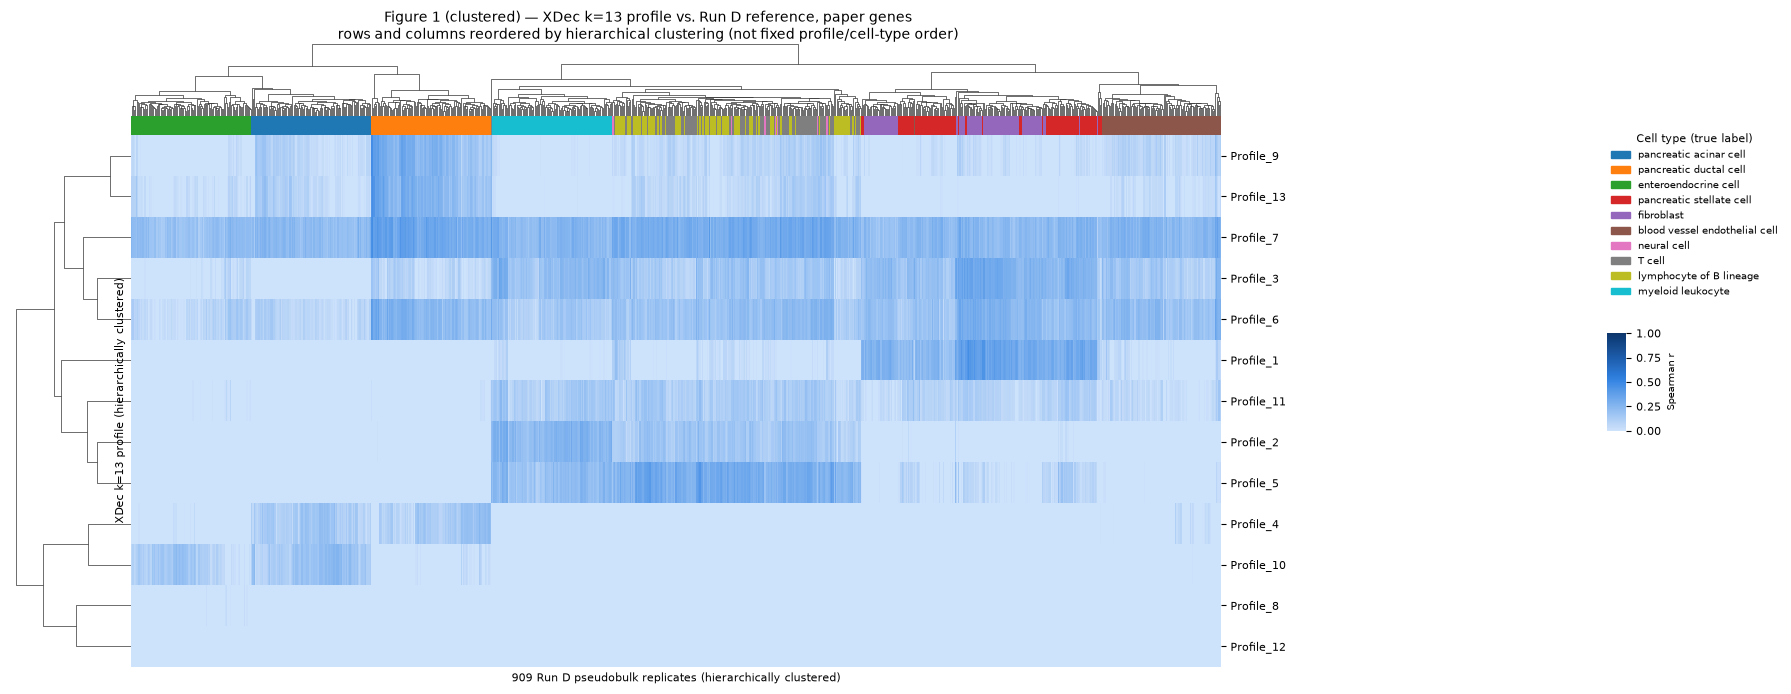

saved xdec_autotuned_n150/figures/fig10_xdec_k13_profile_reference_CLUSTERED.png


In [3]:
genes_1 = [g for g in paper_genes if g in reference_means.index and g in profiles_k13.index]
print(f"Figure 1: {len(genes_1)} shared paper-gene probes (same gene list as notebook 08's fixed-order version)")

combined_1 = pd.concat([reference_means.loc[genes_1], profiles_k13.loc[genes_1, profile_order]], axis=1)
corr_1_full = combined_1.corr(method="spearman")
corr_1 = corr_1_full.loc[profile_order, pb_order]
if not np.isfinite(corr_1.to_numpy()).all():
    raise ValueError("Undefined correlations in Figure 1")

grid = sns.clustermap(
    corr_1, row_cluster=True, col_cluster=True, metric="euclidean", method="average",
    col_colors=pb_cell_types.loc[pb_order].map(cell_palette).to_numpy(),
    cmap=seq_blue, vmin=0.0, vmax=1.0,
    xticklabels=False, yticklabels=True, figsize=(13, 6.5),
    cbar_kws={"label": "Spearman r", "ticks": [0, 0.25, 0.5, 0.75, 1]}, dendrogram_ratio=(0.10, 0.12),
)
grid.ax_heatmap.set_xlabel(f"{len(pb_order)} Run D pseudobulk replicates (hierarchically clustered)")
grid.ax_heatmap.set_ylabel("XDec k=13 profile (hierarchically clustered)")
grid.ax_heatmap.yaxis.set_label_position("left")
grid.ax_heatmap.tick_params(axis="y", rotation=0)

handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
legend = grid.ax_heatmap.legend(
    handles, cell_type_order, title="Cell type (true label)", bbox_to_anchor=(1.35, 1.02),
    loc="upper left", fontsize=7, title_fontsize=8, frameon=False,
)
grid.fig.suptitle("Figure 1 (clustered) — XDec k=13 profile vs. Run D reference, paper genes\n"
                   "rows and columns reordered by hierarchical clustering (not fixed profile/cell-type order)",
                   y=1.03, fontsize=10)
grid.fig.canvas.draw()
bbox = legend.get_window_extent(grid.fig.canvas.get_renderer()).transformed(grid.fig.transFigure.inverted())
grid.cax.set_position([bbox.x0, bbox.y0 - 0.20, 0.015, 0.15])
grid.cax.yaxis.label.set_fontsize(7)

figures_dir = Path("xdec_autotuned_n150/figures")
figures_dir.mkdir(parents=True, exist_ok=True)
fig1_path = figures_dir / "fig10_xdec_k13_profile_reference_CLUSTERED.png"
grid.savefig(fig1_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(grid.fig)
print("saved", fig1_path)


### Figure 2 (clustered)

Figure 2: 3671 shared genes (CIBERSORTx's own auto-selected gene list)


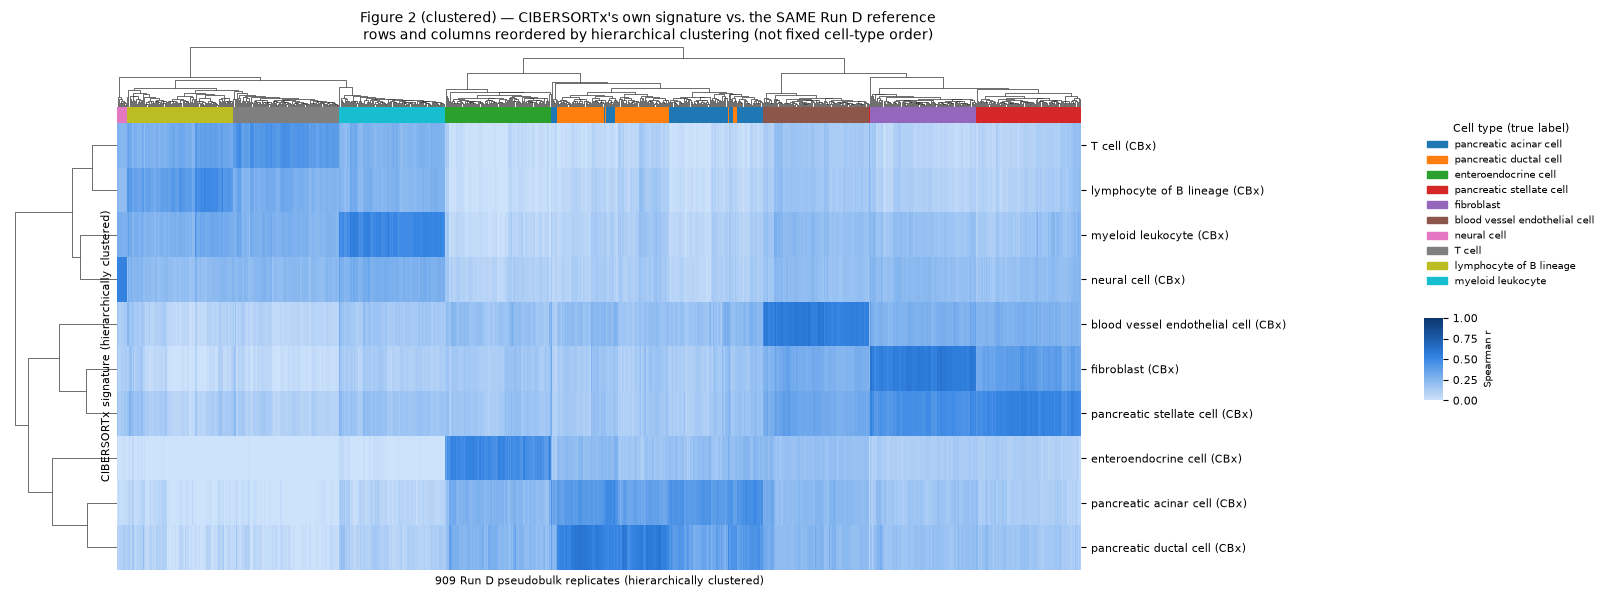

saved xdec_autotuned_n150/figures/fig10_cibersortx_sigmatrix_reference_CLUSTERED.png


In [4]:
sigmatrix_renamed = sigmatrix.rename(columns=lambda c: f"{c} (CBx)")
sig_row_order = [f"{c} (CBx)" for c in cols10]
genes_2 = [g for g in sigmatrix.index if g in reference_means.index]
print(f"Figure 2: {len(genes_2)} shared genes (CIBERSORTx's own auto-selected gene list)")

combined_2 = pd.concat([reference_means.loc[genes_2], sigmatrix_renamed.loc[genes_2]], axis=1)
expected_cols = len(pb_order) + 10
if combined_2.shape[1] != expected_cols or not combined_2.columns.is_unique:
    raise ValueError(f"Expected {expected_cols} uniquely-named columns")
corr_2_full = combined_2.corr(method="spearman")
corr_2 = corr_2_full.loc[sig_row_order, pb_order]
if not np.isfinite(corr_2.to_numpy()).all():
    raise ValueError("Undefined correlations in Figure 2")

grid = sns.clustermap(
    corr_2, row_cluster=True, col_cluster=True, metric="euclidean", method="average",
    col_colors=pb_cell_types.loc[pb_order].map(cell_palette).to_numpy(),
    cmap=seq_blue, vmin=0.0, vmax=1.0,
    xticklabels=False, yticklabels=True, figsize=(13, 5.5),
    cbar_kws={"label": "Spearman r", "ticks": [0, 0.25, 0.5, 0.75, 1]}, dendrogram_ratio=(0.10, 0.12),
)
grid.ax_heatmap.set_xlabel(f"{len(pb_order)} Run D pseudobulk replicates (hierarchically clustered)")
grid.ax_heatmap.set_ylabel("CIBERSORTx signature (hierarchically clustered)")
grid.ax_heatmap.yaxis.set_label_position("left")
grid.ax_heatmap.tick_params(axis="y", rotation=0)

handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
legend = grid.ax_heatmap.legend(
    handles, cell_type_order, title="Cell type (true label)", bbox_to_anchor=(1.35, 1.02),
    loc="upper left", fontsize=7, title_fontsize=8, frameon=False,
)
grid.fig.suptitle("Figure 2 (clustered) — CIBERSORTx's own signature vs. the SAME Run D reference\n"
                   "rows and columns reordered by hierarchical clustering (not fixed cell-type order)",
                   y=1.04, fontsize=10)
grid.fig.canvas.draw()
bbox = legend.get_window_extent(grid.fig.canvas.get_renderer()).transformed(grid.fig.transFigure.inverted())
grid.cax.set_position([bbox.x0, bbox.y0 - 0.20, 0.015, 0.15])
grid.cax.yaxis.label.set_fontsize(7)

fig2_path = figures_dir / "fig10_cibersortx_sigmatrix_reference_CLUSTERED.png"
grid.savefig(fig2_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(grid.fig)
print("saved", fig2_path)


**Interpretation**

* Figure 2's near-perfect recovery of the immune/stromal/epithelial super-structure, with zero label information supplied to the clustering algorithm, is a strong independent check: it means this three-way grouping is a real, strong signal in the correlation matrix itself — consistent with (and now confirmed by a completely different method than) every fixed-order heatmap throughout this project.
* Figure 1's messier clustering is informative mainly through its row dendrogram: the broad/ambiguous profiles notebook 08 flagged by eye (high correlation with many reference types) and the dead/near-zero profiles it also flagged both turn out to cluster tightly with each other in Figure 1's row dendrogram — i.e., "ambiguous" and "dead" are not just two labels a human analyst assigned looking at numbers, they are two genuinely distinct, internally-consistent statistical clusters within the k=13 fit.
* Net takeaway for anyone deciding how much to trust k=13 (or any XDec fit) against CIBERSORTx: the clustering comparison makes the gap between a supervised and an unsupervised method unusually visible — CIBERSORTx's structure is recoverable from the data alone; XDec's requires knowing in advance which profile is which; and even then, several profiles explain each other better than they explain any single reference cell type.
